# IT Help Desk | Data Engineering Pipeline
### 01 — Exploratory Data Analysis (EDA)

**Tech stack:** Databricks · PySpark · Python · Unity Catalog · Delta Lake (downstream layers)

**Source:** [Synthetic IT Support Tickets (Kaggle)](https://www.kaggle.com/datasets/ahsanneural/synthetic-it-support-tickets)  
**Dataset:** 100,000 *synthetic* support tickets, with records dated 2022–2025.

## Project objective

The main objective of this project is to develop a reproducible data engineering workflow ( Medallion ) that ingests a support-ticket dataset, checks its quality, transforms records according to documented business rules, and prepares analytical datasets for operational reporting.

**Planned pipeline:**

1. **EDA (this notebook):** Explore source schema, completeness, uniqueness, valid categories, and ticket distributions.
2. **Bronze:** Ingest source files into Delta tables with ingestion metadata while preserving raw source values.
3. **Silver:** Standardize and validate data, retain valid missing values, and enrich fields for downstream analytics.
4. **Gold:** Build business-ready aggregates for ticket volumes, resolution rates, resolution durations, and survey satisfaction.

## 1. Imports ,environment and source configuration


In [0]:
from pyspark.sql import functions as F
from pyspark.sql.types import (StructType, StructField, StringType, TimestampType,DoubleType, IntegerType)
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

CATALOG = "db_projects"
SCHEMA = "data_engineering"
VOLUME = "helpdesk_raw"
CSV_PATH = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}/synthetic_it_support_tickets.csv"


spark.sql(f"CREATE CATALOG IF NOT EXISTS {CATALOG}")
spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{SCHEMA}")
spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.{VOLUME}")

print("Source file:", CSV_PATH)

Source file: /Volumes/db_projects/data_engineering/helpdesk_raw/synthetic_it_support_tickets.csv


## 2. Load the source dataset

**Important source semantics:** `NA` is the valid region code for *North America*, not a missing value. Missing resolution information is expected for unresolved tickets. A `csat_score` of `0` means *no survey response* (the documented valid rating scale is 1–5).

In [0]:
tickets = spark.read.csv(
    CSV_PATH,
    header=True,   # 1st line contains Column Names 
    inferSchema=True  # Tell Databricks to identify the data types of each column
)

display(tickets.head(5))

ticket_id,created_at,customer_id,customer_segment,channel,product_area,issue_type,priority,status,sla_plan,initial_message,agent_first_reply,resolution_summary,resolution_time_hours,reopened,customer_sentiment,csat_score,has_attachment,platform,region
TCKT_000001,2024-01-31T05:14:27.000Z,CUST_00861,individual,email,data_export,account_access,low,resolved,standard,I cannot log in; the system says my password is incorrect.,Sorry to hear you're having trouble accessing your account. We will look into this and get back to you within the next 48 hours.,Reset account credentials and confirmed successful login.,36.53,0,very_negative,1,0,android,EU
TCKT_000002,2024-10-20T06:15:49.000Z,CUST_00770,individual,in_app,billing,security_concern,medium,closed_no_action,standard,I noticed a suspicious login on my account.,We take security very seriously. Our team is reviewing this and will follow up within 24 hours.,Ticket closed without further action after no response from the customer.,238.32,0,neutral,3,0,web,NA
TCKT_000003,2024-06-18T21:35:54.000Z,CUST_02559,small_business,chat,api_integration,bug,low,in_progress,standard,The api integration feature is not saving my changes.,Thanks for reporting this bug. We will look into this and get back to you within the next 48 hours.,null,null,0,neutral,3,0,android,MEA
TCKT_000004,2025-12-25T15:59:52.000Z,CUST_03557,education,chat,analytics_dashboard,account_access,medium,in_progress,standard,I cannot log in; the system says my password is incorrect.,Sorry to hear you're having trouble accessing your account. Our team is reviewing this and will follow up within 24 hours.,null,null,0,positive,5,1,android,LATAM
TCKT_000005,2023-08-27T16:08:33.000Z,CUST_09556,enterprise,phone_transcript,login_auth,billing_problem,low,resolved,gold,My invoice amount is incorrect compared to the plan I selected.,Thanks for reaching out about the billing issue. We will look into this and get back to you within the next 48 hours.,Adjusted the invoice and issued a refund where applicable.,61.32,0,very_negative,2,0,web,NA


## 3. Dataset Analysis

Determine the dataset size, time coverage, and uniqueness of the business key (`ticket_id`)

In [0]:
ticket_count = tickets.count()
print(f"Total tickets: {ticket_count:,}")
print(f"Total columns: {len(tickets.columns)}")

tickets.select(F.min("created_at").alias("first_created_at"),F.max("created_at").alias("last_created_at")).show(truncate=False)

Total tickets: 100,000
Total columns: 20
+-------------------+-------------------+
|first_created_at   |last_created_at    |
+-------------------+-------------------+
|2022-01-01 00:16:58|2025-12-30 23:45:45|
+-------------------+-------------------+



In [0]:
# Different checks: completely identical rows vs. repeated business keys.
exact_duplicate_rows = ticket_count - tickets.dropDuplicates().count()

duplicate_ticket_ids = (
    tickets.groupBy("ticket_id")
    .count()
    .filter(F.col("count") > 1)
)

print("Exact duplicate rows:", exact_duplicate_rows)
print("Ticket IDs with duplicates:", duplicate_ticket_ids.count())
display(duplicate_ticket_ids.limit(20))

Exact duplicate rows: 0
Ticket IDs with duplicates: 0


ticket_id,count


**Interpretation.** The supplied CSV contains 100,000 records and 20 columns. Its observed date range is **2022-01-01 to 2025-12-30**. It has no repeated `ticket_id` values and no identical duplicate rows.


## 4. Distribution of tickets

Profile ticket priority, category, and status. Priority has a defined business order, `urgent`, `high`, `medium`, `low`.

In [0]:
priority_sort = (
    F.when(F.col("priority") == "urgent", 1)
     .when(F.col("priority") == "high", 2)
     .when(F.col("priority") == "medium", 3)
     .when(F.col("priority") == "low", 4)
     .otherwise(99)
)

priority_counts = (
    tickets.groupBy("priority")
    .agg(F.count("*").alias("ticket_count"))
    .withColumn("pct_of_tickets", F.round(F.col("ticket_count") / ticket_count * 100, 2))
    .orderBy(priority_sort)
)

display(priority_counts)

priority,ticket_count,pct_of_tickets
urgent,5087,5.09
high,19865,19.87
medium,35313,35.31
low,39735,39.74


In [0]:
priority_by_issue = (
    tickets.groupBy("priority", "issue_type")
    .count()
    .orderBy(priority_sort, F.desc("count"))
)

display(priority_by_issue)

priority,issue_type,count
urgent,account_access,736
urgent,how_to,655
urgent,billing_problem,631
urgent,performance,629
urgent,security_concern,626
urgent,feature_request,609
urgent,other,602
urgent,bug,599
high,how_to,2540
high,performance,2512


In [0]:
status_counts = (
    tickets.groupBy("status")
    .agg(F.count("*").alias("ticket_count"))
    .withColumn("pct_of_tickets", F.round(F.col("ticket_count") / ticket_count * 100, 2))
    .orderBy(F.desc("ticket_count"))
)

display(status_counts)

status,ticket_count,pct_of_tickets
resolved,50131,50.13
in_progress,19783,19.78
on_hold,10165,10.17
closed_no_action,9982,9.98
open,9939,9.94


### Key findings — ticket distribution

- **Low and medium** priorities dominate the data: 39,735 and 35,313 tickets respectively. **Urgent** cases are much less common (5,087).
- **Account access** is the largest issue category among urgent tickets (736), while **how-to** issues lead among high-priority tickets (2,540).
- `resolved` (50,131) is the largest status group. However, `closed_no_action` (9,982) must remain distinct from successfully resolved tickets when calculating resolution rates.

## 5. Missing values and resolution consistency

`resolution_summary` and `resolution_time_hours` are absent for unresolved tickets.

In [0]:
# do NOT treat 'NA' as missing.
missing_counts = tickets.select([
    F.sum(
        (
            F.col(c).isNull()
            | F.lower(F.trim(F.col(c).cast("string"))).isin("", "null", "nan")
        ).cast("int")
    ).alias(c)
    for c in tickets.columns
]).first().asDict()

missing_rows = [
    (column, int(count), round(100 * count / ticket_count, 2))
    for column, count in missing_counts.items()
    if count is not None and count > 0
]

if missing_rows:
    missing_profile = spark.createDataFrame(
        missing_rows,
        schema="column_name string, missing_count long, missing_pct double"
    ).orderBy(F.desc("missing_count"))
    display(missing_profile)
else:
    print("No missing or missing-like values detected.")

column_name,missing_count,missing_pct
resolution_summary,39887,39.89
resolution_time_hours,39887,39.89


In [0]:
# Verify whether missing resolution fields align with unresolved statuses.
resolution_by_status = (
    tickets.groupBy("status")
    .agg(
        F.count("*").alias("total_tickets"),
        F.sum(F.col("resolution_time_hours").isNull().cast("int")).alias("missing_resolution_time"),
        F.sum(F.col("resolution_summary").isNull().cast("int")).alias("missing_resolution_summary"),
        F.round(F.avg("resolution_time_hours"), 2).alias("avg_recorded_resolution_hours")
    )
    .orderBy(F.desc("total_tickets"))
)

display(resolution_by_status)

status,total_tickets,missing_resolution_time,missing_resolution_summary,avg_recorded_resolution_hours
resolved,50131,0,0,27.77
in_progress,19783,19783,19783,null
on_hold,10165,10165,10165,null
closed_no_action,9982,0,0,131.62
open,9939,9939,9939,null


In [0]:
completed_statuses = ["resolved", "closed_no_action"]
unresolved_statuses = ["open", "in_progress", "on_hold"]

resolution_consistency = tickets.agg(
    F.sum(
        F.when(
            F.col("status").isin(completed_statuses)
            & (F.col("resolution_time_hours").isNull() | F.col("resolution_summary").isNull()), 1
        ).otherwise(0)
    ).alias("completed_tickets_missing_resolution_fields"),
    F.sum(
        F.when(
            F.col("status").isin(unresolved_statuses)
            & (F.col("resolution_time_hours").isNotNull() | F.col("resolution_summary").isNotNull()), 1
        ).otherwise(0)
    ).alias("unresolved_tickets_with_resolution_fields")
)

display(resolution_consistency)

completed_tickets_missing_resolution_fields,unresolved_tickets_with_resolution_fields
0,0


### Key finding — documented missingness

Exactly **39,887 tickets (39.89%)** have missing resolution summaries and resolution times. Inspection by status shows these correspond to the `open`, `in_progress`, and `on_hold` groups. Both `resolved` and `closed_no_action` records contain resolution information in the current source.

## 6. Region codes and CSV parsing integrity

The region values are `EU` (Europe), `NA` (North America), `MEA` (Middle East & Africa), `LATAM` (Latin America), and `APAC` (Asia-Pacific).

**Source parsing pitfall:** Pandas defaults can interpret the string `NA` as null. PySpark retains this region code. When using Pandas for cross-checking, explicitly prevent the misclassification. Do not standardize `NA` to a missing value.

In [0]:
region_counts = (
    tickets.groupBy("region")
    .count()
    .orderBy(F.desc("count"))
)

display(region_counts)

region,count
MEA,20151
NA,19997
EU,19960
LATAM,19959
APAC,19933


In [0]:
# Optional cross-library check for this demo dataset (100k rows).
# For large datasets, keep the analysis distributed in Spark.
pandas_tickets = pd.read_csv(
    CSV_PATH,
    keep_default_na=False,
    na_values=[""]
)

print("Pandas dataset shape:", pandas_tickets.shape)
print("Pandas region null count:", pandas_tickets["region"].isna().sum())
print(pandas_tickets["region"].value_counts(dropna=False).to_string())

Pandas dataset shape: (100000, 20)
Pandas region null count: 0
region
MEA      20151
NA       19997
EU       19960
LATAM    19959
APAC     19933


## 7. Customer satisfaction (CSAT)

The source explicitly defines a **1–5 satisfaction scale** and `0` as **no survey response**.

In [0]:
display(
    tickets.groupBy("csat_score")
    .count()
    .orderBy("csat_score")
)

csat_kpis = tickets.agg(
    F.count("*").alias("total_tickets"),
    F.sum(F.when(F.col("csat_score").between(1, 5), 1).otherwise(0)).alias("survey_responses"),
    F.sum(F.when(F.col("csat_score") == 0, 1).otherwise(0)).alias("no_survey_response"),
    F.round(F.avg(F.when(F.col("csat_score").between(1, 5), 1).otherwise(0)) * 100, 2)
        .alias("survey_response_rate_pct"),
    F.round(F.avg(F.when(F.col("csat_score").between(1, 5), F.col("csat_score"))), 2)
        .alias("avg_csat_respondents_only")
)

display(csat_kpis)

csat_score,count
0,29941
1,5815
2,14871
3,20453
4,17321
5,11599


total_tickets,survey_responses,no_survey_response,survey_response_rate_pct,avg_csat_respondents_only
100000,70059,29941,70.06,3.2


## 9. Exploratory visualizations Graphs

In [0]:
# Prepare small aggregated datasets for plotting.
priority_order = ["urgent", "high", "medium", "low"]
priority_colors = ["#D94848", "#E99545", "#E4BC52", "#48A889"]

priority_plot = (
    tickets.groupBy("priority").count().toPandas()
    .set_index("priority").reindex(priority_order).fillna(0).reset_index()
)
priority_plot["count"] = priority_plot["count"].astype(int)

monthly_plot = (
    tickets.groupBy(F.date_trunc("month", "created_at").alias("month"))
    .count()
    .orderBy("month")
    .toPandas()
)
monthly_plot["month"] = pd.to_datetime(monthly_plot["month"])

issue_plot = (
    tickets.groupBy("issue_type")
    .count()
    .orderBy(F.desc("count"))
    .toPandas()
)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#64748B",
    "xtick.color": "#64748B",
    "ytick.color": "#334155",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "savefig.facecolor": "white"
})

def style_axis(ax, axis="y"):
    ax.set_axisbelow(True)
    ax.grid(axis=axis, color="#E8EDF3", linewidth=0.8)
    ax.tick_params(axis="both", length=0)

### 9.1 Ticket distribution by priority

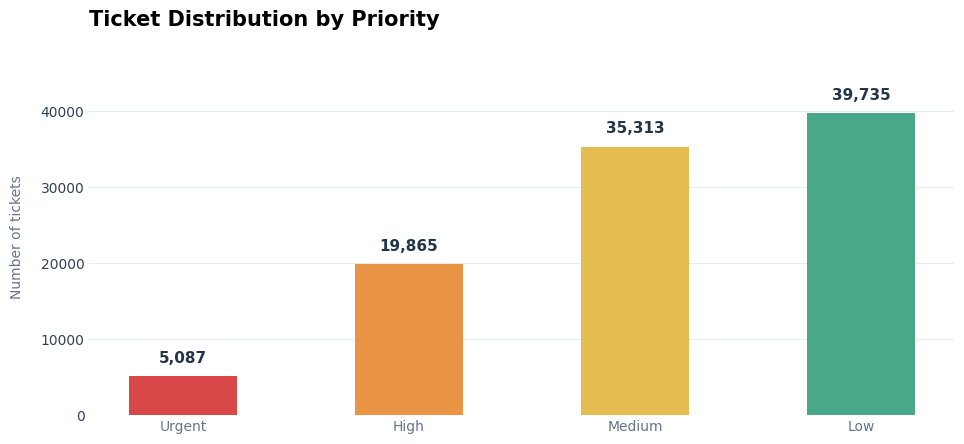

In [0]:
fig, ax = plt.subplots(figsize=(10, 4.8))

bars = ax.bar(
    [p.title() for p in priority_plot["priority"]],
    priority_plot["count"],
    color=priority_colors,
    width=0.48
)

ax.bar_label(
    bars,
    labels=[f"{v:,}" for v in priority_plot["count"]],
    padding=8,
    fontsize=11,
    fontweight="bold",
    color="#243449"
)

ax.set_title("Ticket Distribution by Priority", loc="left", pad=24)
ax.set_ylabel("Number of tickets", labelpad=12)
ax.set_ylim(0, priority_plot["count"].max() * 1.18)
style_axis(ax)

fig.tight_layout(pad=2)
plt.show()

### 9.2 Monthly ticket volume

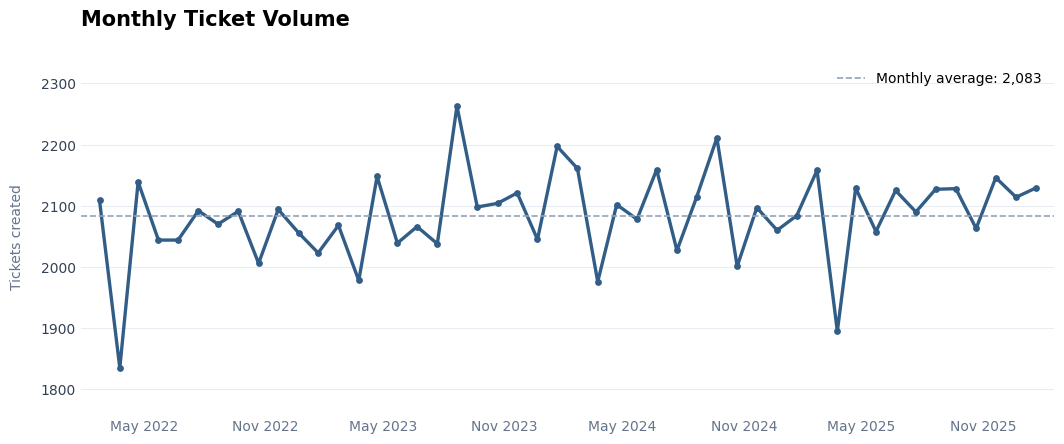

In [0]:
fig, ax = plt.subplots(figsize=(11, 4.8))

ax.plot(
    monthly_plot["month"],
    monthly_plot["count"],
    color="#315D86",
    linewidth=2.4
)

ax.scatter(
    monthly_plot["month"],
    monthly_plot["count"],
    color="#315D86",
    s=15,
    zorder=3
)

ax.axhline(
    monthly_plot["count"].mean(),
    color="#94A3B8",
    linestyle="--",
    linewidth=1.2,
    label=f"Monthly average: {monthly_plot['count'].mean():,.0f}"
)

ax.set_title("Monthly Ticket Volume", loc="left", pad=24)
ax.set_ylabel("Tickets created", labelpad=12)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(frameon=False, loc="upper right")
ax.margins(x=0.02, y=0.18)

style_axis(ax)
fig.autofmt_xdate(rotation=0)
fig.tight_layout(pad=2)
plt.show()

### 9.3 Ticket distribution by issue type

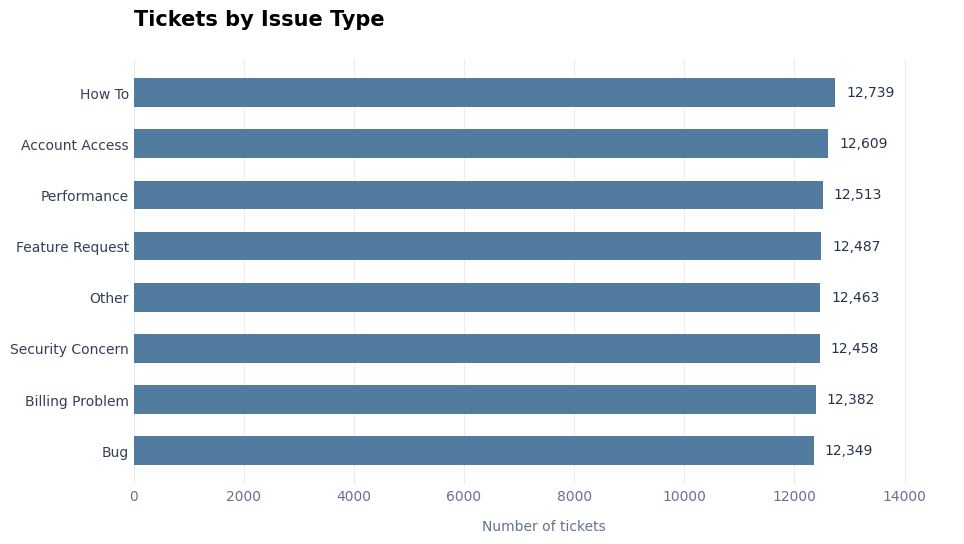

In [0]:
fig, ax = plt.subplots(figsize=(10, 5.8))

labels = issue_plot["issue_type"].str.replace("_", " ", regex=False).str.title()

bars = ax.barh(
    labels,
    issue_plot["count"],
    color="#517B9F",
    height=0.56
)
ax.invert_yaxis()

ax.bar_label(
    bars,
    labels=[f"{v:,}" for v in issue_plot["count"]],
    padding=8,
    fontsize=10,
    color="#243449"
)

ax.set_title("Tickets by Issue Type", loc="left", pad=24)
ax.set_xlabel("Number of tickets", labelpad=12)
ax.set_xlim(0, issue_plot["count"].max() * 1.17)

style_axis(ax, axis="x")
fig.tight_layout(pad=2)
plt.show()

## 10. EDA conclusions 

### Verified observations

- The supplied source contains **100,000 unique tickets across 20 columns**.
- The observed ticket creation timestamps range from **2022-01-01** to **2025-12-30**.
- **Low** and **medium** priorities collectively account for most tickets, while urgent tickets are comparatively rare.
- **39,887 records (39.89%)** have null resolution fields. These are associated with `open`, `in_progress`, and `on_hold` statuses in the current dataset.
- **29,941 tickets** have `csat_score = 0`, which the source documentation explicitly defines as no survey response.
- The regional code **`NA` means North America**. It must not be converted to a null value by CSV parsing.

### Design decisions for the Medallion Layers

1. **Bronze:** Preserve source values and maintain ingestion metadata for traceability.
2. **Silver:** Validate identifiers and categories; standardize text and timestamps; retain meaningful nulls; keep `region = 'NA'`;
3. **Gold:** Publish interpretable KPIs such as ticket volumes, successful resolution rate, mean resolution time (with clear status scope), survey response rate, and average respondent CSAT.